In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns 
data=pd.read_csv("apollo_appointments_fact.csv")
Appointment_data=pd.DataFrame(data)
Data=pd.read_csv("apollo_doctors_dim.csv")
Apollo_doctor=pd.DataFrame(Data)
Appointment_data["appointment_date"]=pd.to_datetime(Appointment_data["appointment_date"])
Appointment_data["Appointment_Year"]=Appointment_data["appointment_date"].dt.year
Appointment_data["Appointment_MonthName"]=Appointment_data["appointment_date"].dt.month_name()


In [2]:
Appointment_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 75000 entries, 0 to 74999
Data columns (total 54 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   appointment_id              75000 non-null  str           
 1   patient_id                  75000 non-null  str           
 2   doctor_id                   75000 non-null  str           
 3   appointment_date            75000 non-null  datetime64[us]
 4   appointment_day             75000 non-null  str           
 5   appointment_day_of_week     75000 non-null  int64         
 6   appointment_month           75000 non-null  int64         
 7   appointment_quarter         75000 non-null  str           
 8   appointment_year            75000 non-null  int64         
 9   appointment_hour            75000 non-null  int64         
 10  appointment_minute          75000 non-null  int64         
 11  time_slot                   75000 non-null  str           
 12  t

In [3]:
Apollo_doctor.info()

<class 'pandas.DataFrame'>
RangeIndex: 320 entries, 0 to 319
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   doctor_id              320 non-null    str    
 1   doctor_name            320 non-null    str    
 2   specialty              320 non-null    str    
 3   qualification          320 non-null    str    
 4   experience_years       320 non-null    int64  
 5   city                   320 non-null    str    
 6   state                  320 non-null    str    
 7   hospital_name          320 non-null    str    
 8   consultation_fee       320 non-null    int64  
 9   rating                 320 non-null    float64
 10  total_reviews          320 non-null    int64  
 11  available_days         320 non-null    str    
 12  avg_slot_duration_min  320 non-null    int64  
 13  accepts_insurance      320 non-null    str    
 14  teleconsult_enabled    320 non-null    str    
dtypes: float64(1), in

# Business Overview

## 1. How is appointment volume trending across months and quarters from 2022 to 2024?

In [4]:

# Convert appointment date to datetime
Appointment_data["appointment_date"] = pd.to_datetime(
    Appointment_data["appointment_date"], errors="coerce"
)

# Filter data from 2022 to 2024
trend_data = Appointment_data[
    Appointment_data["appointment_date"].dt.year.between(2022, 2024)
].copy()

# Monthly appointment volume
trend_data["month"] = trend_data["appointment_date"].dt.to_period("M")

Monthly_volume = trend_data.groupby(
    "month"
).size().reset_index(name="total_appointments")

Monthly_volume["month"] = Monthly_volume["month"].astype(str)

# Quarterly appointment volume
trend_data["quarter"] = trend_data["appointment_date"].dt.to_period("Q")

Quarterly_volume = trend_data.groupby(
    "quarter"
).size().reset_index(name="total_appointments")

Quarterly_volume["quarter"] = Quarterly_volume["quarter"].astype(str)

print("Monthly Appointment Volume")
display(Monthly_volume)

print("Quarterly Appointment Volume")
display(Quarterly_volume)


Monthly Appointment Volume


,month,total_appointments
0,2022-01,2426
1,2022-02,2012
2,2022-03,2085
3,2022-04,1926
4,2022-05,2033
5,2022-06,1823
6,2022-07,1833
7,2022-08,1835
8,2022-09,2115
9,2022-10,2206


Quarterly Appointment Volume


,quarter,total_appointments
0,2022Q1,6523
1,2022Q2,5782
2,2022Q3,5783
3,2022Q4,6780
4,2023Q1,6487
5,2023Q2,5862
6,2023Q3,5707
7,2023Q4,6998
8,2024Q1,6538
9,2024Q2,5899


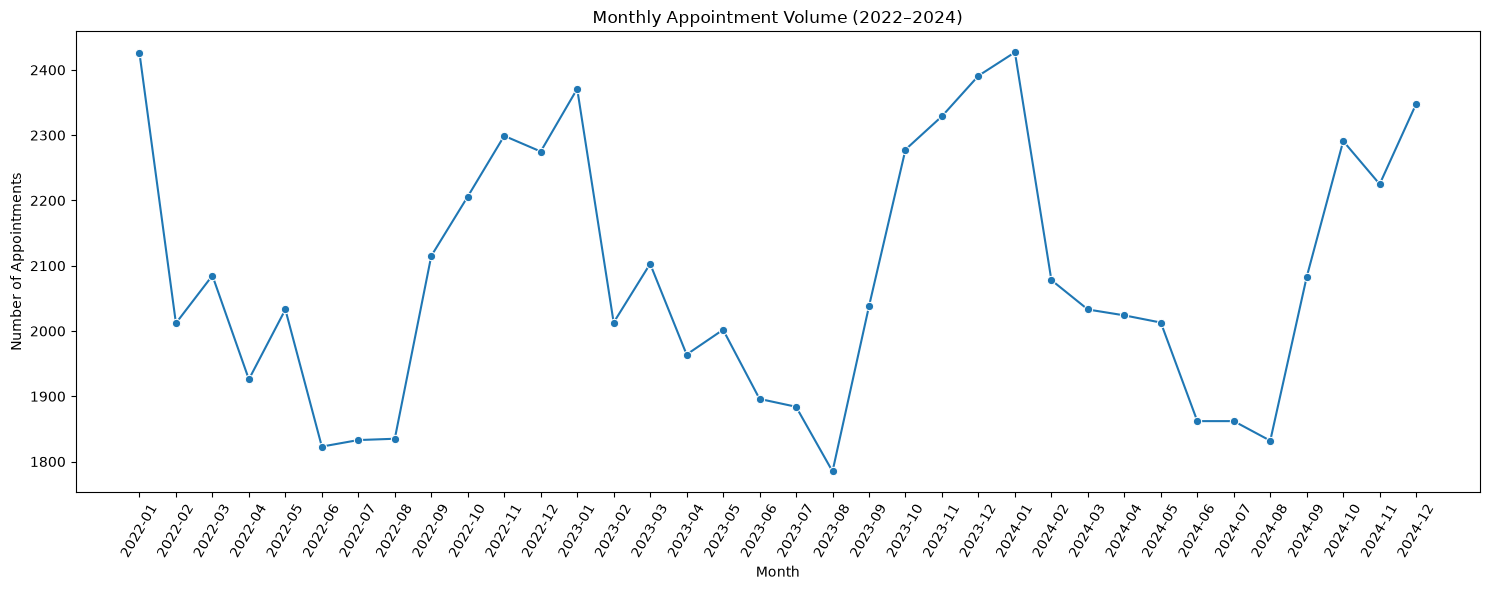

In [5]:
#Monthly trend visualization

plt.figure(figsize=(15, 6))

sns.lineplot(
    data=Monthly_volume,
    x="month",
    y="total_appointments",
    marker="o"
)

plt.title("Monthly Appointment Volume (2022–2024)")
plt.xlabel("Month")
plt.ylabel("Number of Appointments")
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()


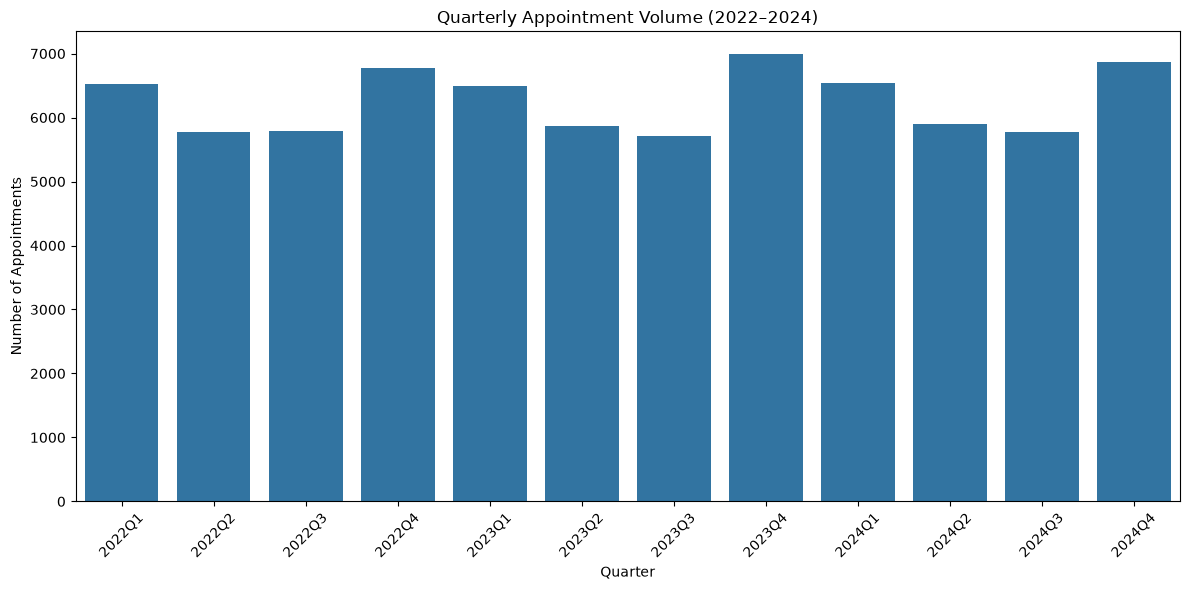

In [6]:
#Quarterly trend visualization

plt.figure(figsize=(12, 6))

sns.barplot(
    data=Quarterly_volume,
    x="quarter",
    y="total_appointments",
    errorbar=None
)

plt.title("Quarterly Appointment Volume (2022–2024)")
plt.xlabel("Quarter")
plt.ylabel("Number of Appointments")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 2.What is the split of outcomes across completed, no-show, cancelled, and scheduled appointments? 

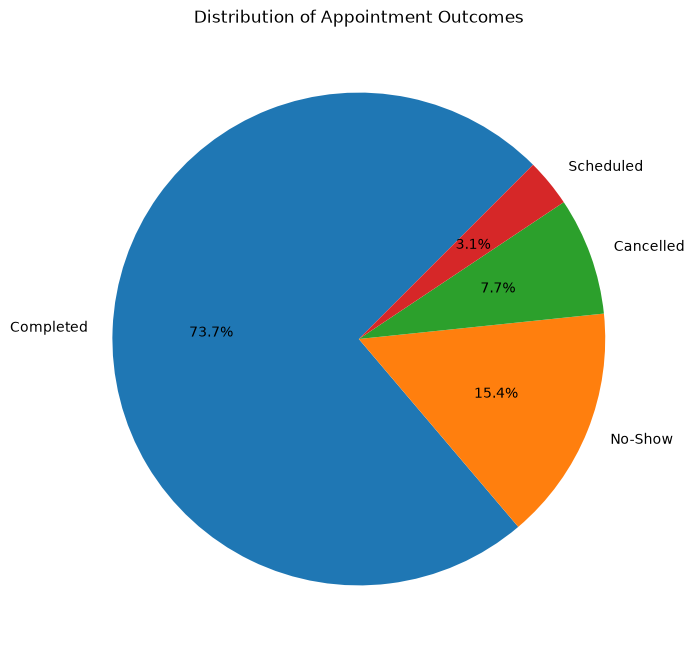

In [7]:
status_counts = Appointment_data["appointment_status"].value_counts()
plt.figure(figsize=(8,8))
plt.pie(
    status_counts.values,
    labels=status_counts.index,
    autopct="%1.1f%%",
    startangle=45
)
plt.title("Distribution of Appointment Outcomes")

plt.show()



## 3.Which booking channels drive the highest volume and how does the channel mix look? 

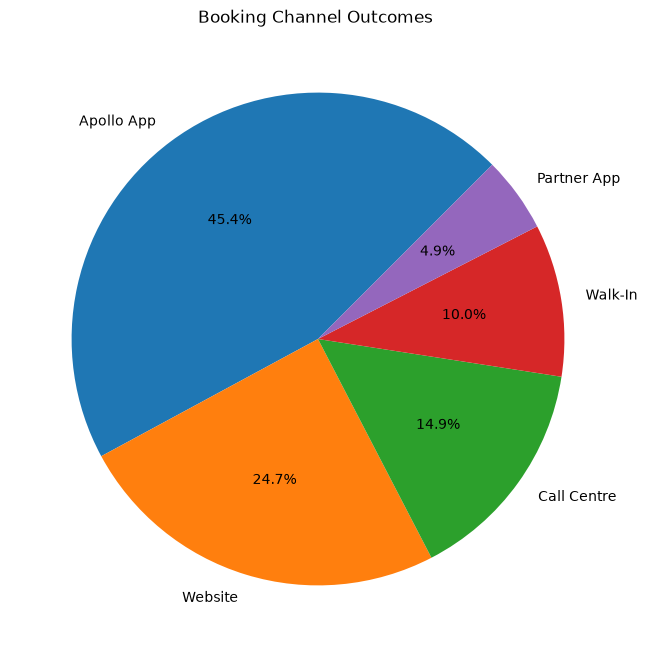

In [8]:
Appointment_data["booking_channel"]
channel_count=Appointment_data["booking_channel"].value_counts()
plt.figure(figsize=(8,8))
plt.pie(channel_count.values,
       labels=channel_count.index,
        autopct="%1.1f%%",
        startangle=45
       )
plt.title("Booking Channel Outcomes ")
plt.show()


## No-Show Analysis 

 ## 1. Which specialties and cities have the highest and lowest no-show rates? 

In [9]:
eligible_appointments = Appointment_data[
    Appointment_data["appointment_status"].isin(
        ["Completed", "No-Show", "Cancelled"]
    )
].copy()
specialty_summary = eligible_appointments.pivot_table(
    index=["specialty"],
    values="no_show_flag",
    aggfunc=["count", "sum"]
)

specialty_summary.columns = ["Total_Eligible", "Total_No_Shows"]

specialty_summary["No_Show_Rate"] = (
    specialty_summary["Total_No_Shows"]
    / specialty_summary["Total_Eligible"]
) * 100

specialty_summary = specialty_summary.sort_values(
    "No_Show_Rate", ascending=False
)

specialty_summary

,Total_Eligible,Total_No_Shows,No_Show_Rate
specialty,,,
Psychiatry,2900,711,24.517241
Dermatology,7566,1608,21.252974
ENT,5211,988,18.959893
Endocrinology,2024,355,17.539526
Ophthalmology,3103,503,16.210119
General Physician,19654,3049,15.513381
Pulmonology,2549,394,15.457042
Orthopaedics,5419,810,14.947407
Gastroenterology,2527,377,14.918876


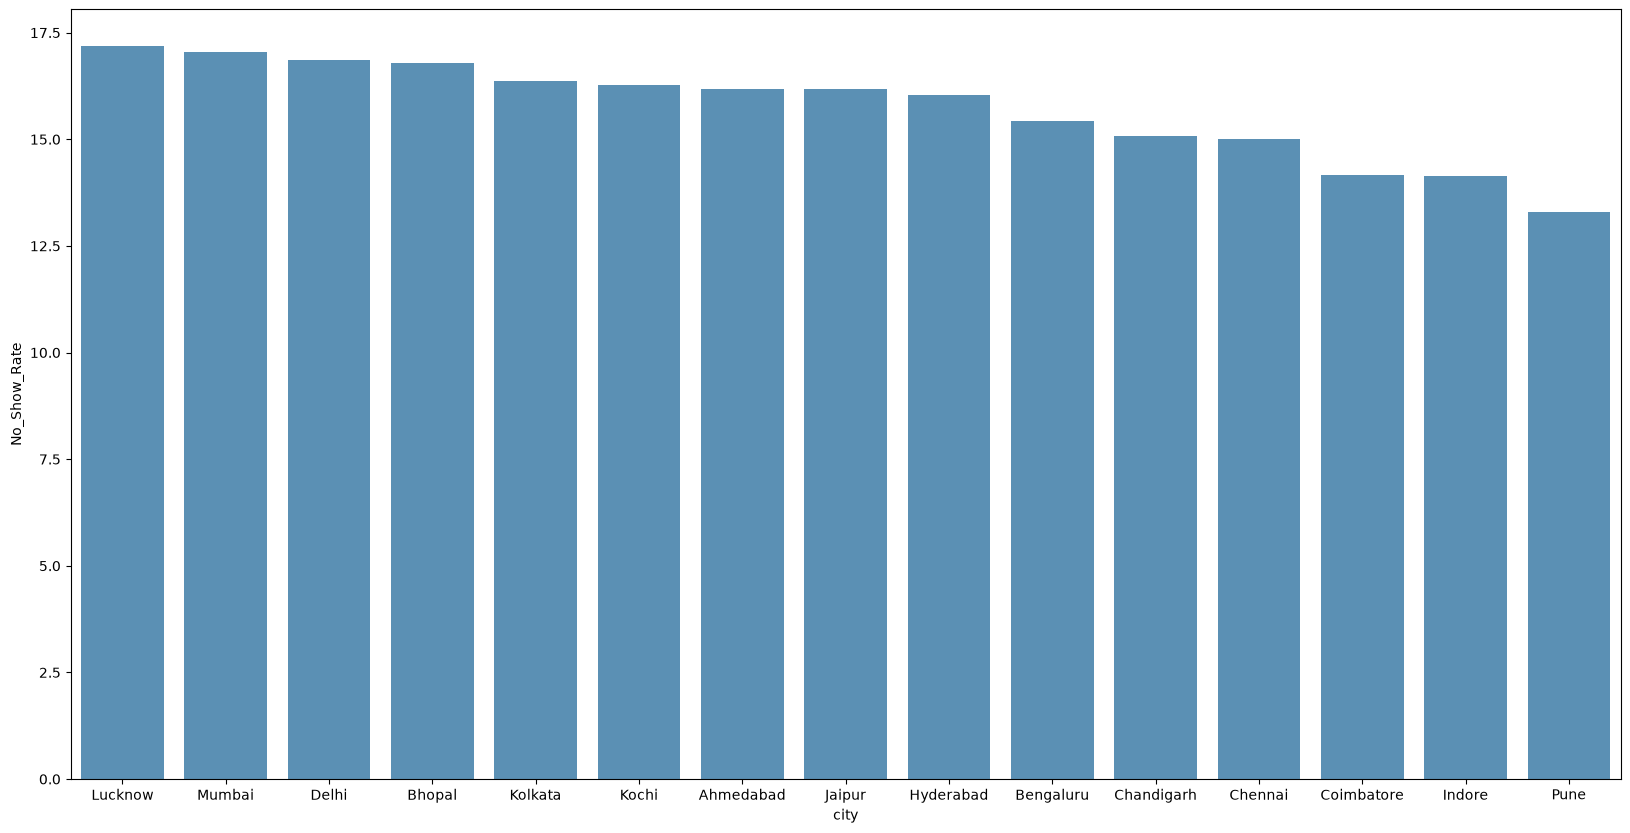

In [10]:
city_summary = eligible_appointments.pivot_table(
    index="city",
    values="no_show_flag",
    aggfunc=["count", "sum"]
)

city_summary.columns = ["Total_Eligible", "Total_No_Shows"]

city_summary["No_Show_Rate"] = (
    city_summary["Total_No_Shows"]
    / city_summary["Total_Eligible"]
) * 100

city_summary = city_summary.sort_values(
    "No_Show_Rate", ascending=False
).reset_index()\


plt.figure(figsize=(20,10))
sns.barplot(
    data=city_summary,
    x="city",
    y="No_Show_Rate",
    alpha=0.8
)

plt.show()

C:\Users\cheta\AppData\Local\Temp\ipykernel_20912\1412422346.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


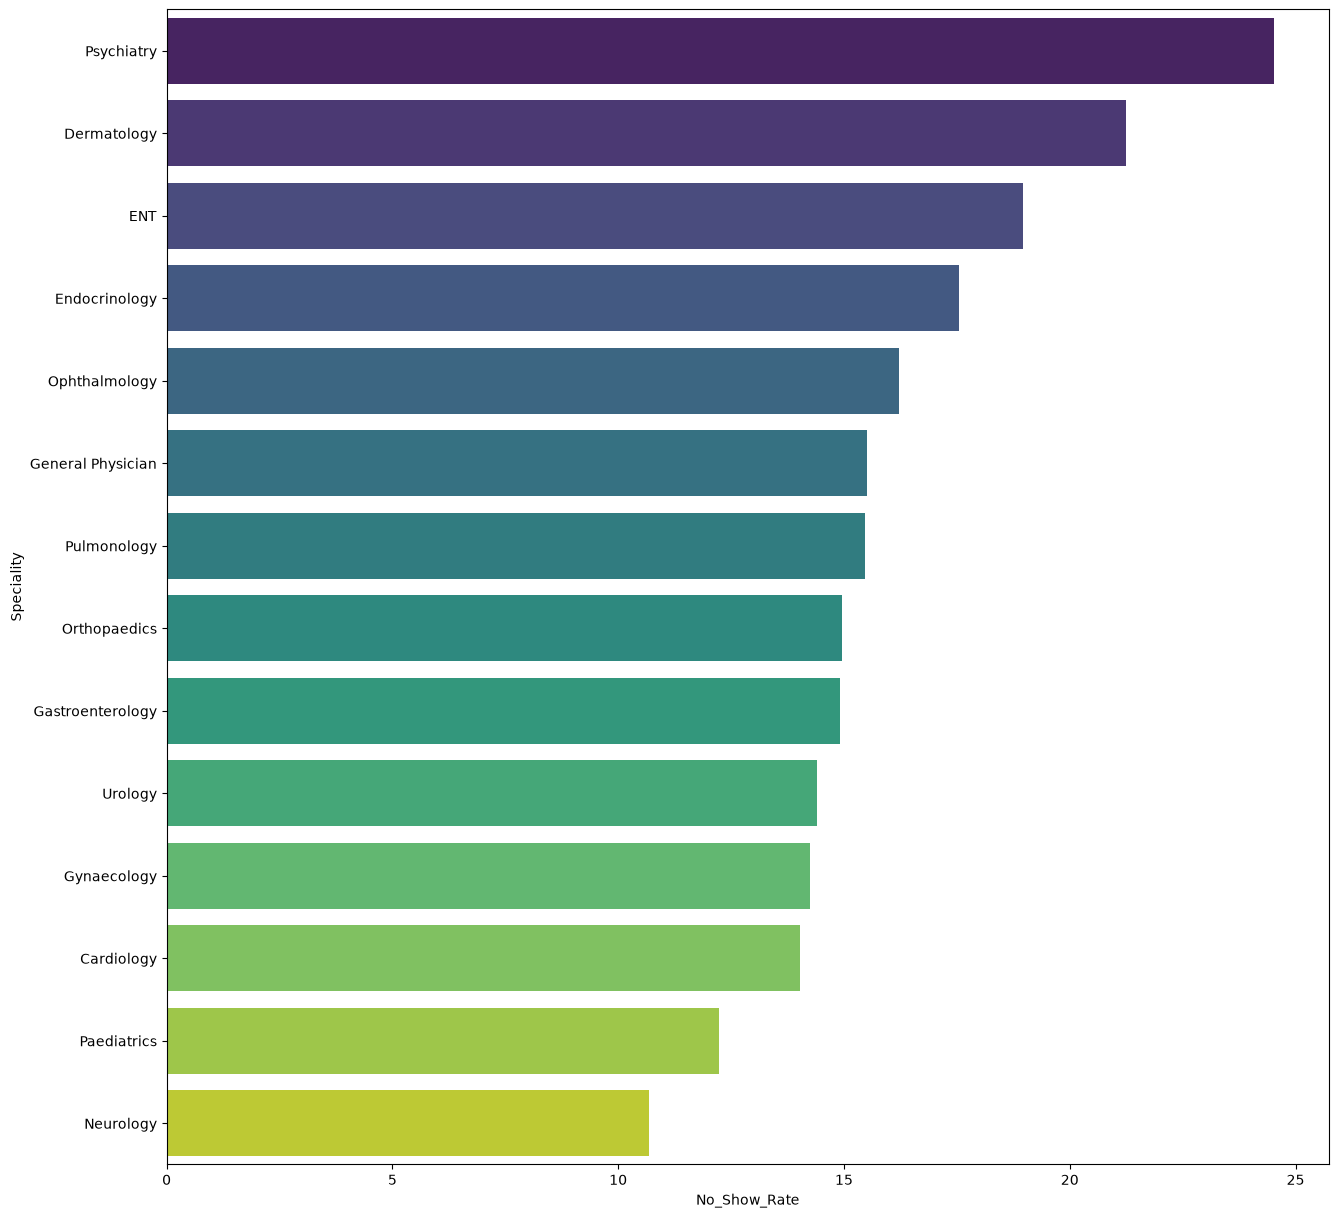

In [11]:
specialty_summary

plt.figure(figsize=(15,15))
sns.barplot(
    data=specialty_summary,
    x="No_Show_Rate",
    y="specialty",
    palette="viridis"
)
plt.ylabel("Speciality")
plt.show()

## 2.How does booking lead time affect the probability of a no-show? 

In [12]:

# Create booking lead-time groups
bins = [0, 1, 7, 14, 30, float("inf")]

labels = [
    "0–1 days",
    "2–7 days",
    "8–14 days",
    "15–30 days",
    "More than 30 days"
]

eligible_appointments["Lead_Time_Group"] = pd.cut(
    eligible_appointments["booking_lead_days"],
    bins=bins,
    labels=labels
)

# Calculate eligible appointments and no-show counts
lead_time_summary = eligible_appointments.groupby(
    "Lead_Time_Group", observed=False
).agg(
    Total_Eligible=("no_show_flag", "count"),
    Total_No_Shows=("no_show_flag", "sum")
)

# Calculate observed no-show probability as a percentage
lead_time_summary["No_Show_Probability"] = (
    lead_time_summary["Total_No_Shows"]
    / lead_time_summary["Total_Eligible"]
) * 100

# Display the summary table
lead_time_summary


,Total_Eligible,Total_No_Shows,No_Show_Probability
Lead_Time_Group,,,
0–1 days,10453,1382,13.221085
2–7 days,30919,4892,15.821986
8–14 days,8758,1648,18.817082
15–30 days,2342,469,20.025619
More than 30 days,0,0,NaN


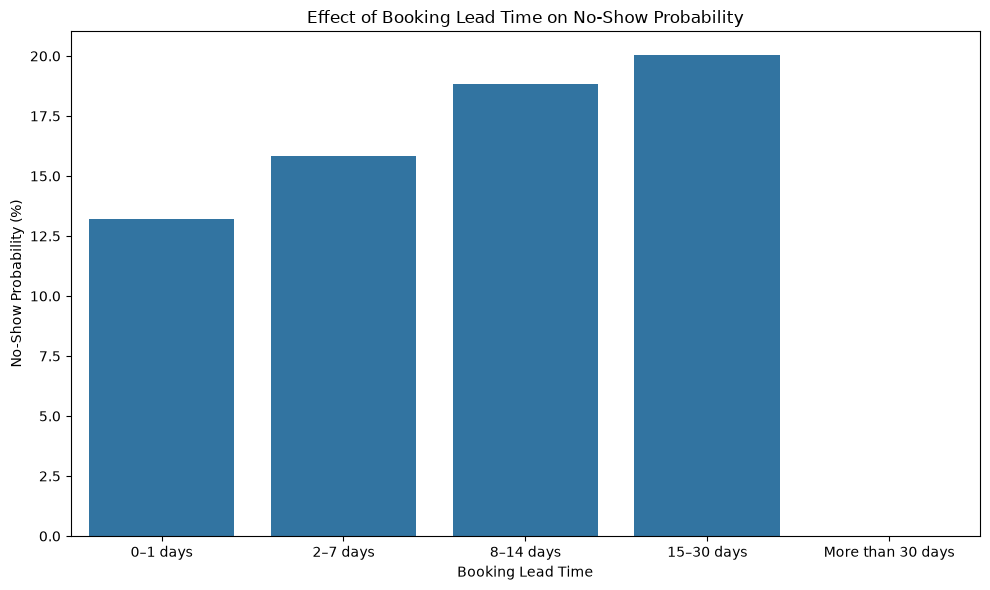

In [13]:

plt.figure(figsize=(10, 6))

sns.barplot(
    data=lead_time_summary.reset_index(),
    x="Lead_Time_Group",
    y="No_Show_Probability"
)

plt.title("Effect of Booking Lead Time on No-Show Probability")
plt.xlabel("Booking Lead Time")
plt.ylabel("No-Show Probability (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 3. Do evening slots, weekends, and longer-lead bookings see higher dropout? 

In [14]:
# Create a weekend/weekday column
eligible_appointments["Day_Type"] = eligible_appointments[
    "appointment_day"
].apply(
    lambda day: "Weekend" if day in ["Saturday", "Sunday"] else "Weekday"
)

# Create a reusable summary function
def no_show_summary(data, group_column):
    summary = data.groupby(group_column, observed=False).agg(
        Total_Eligible=("no_show_flag", "count"),
        Total_No_Shows=("no_show_flag", "sum")
    )

    summary["No_Show_Rate"] = (
        summary["Total_No_Shows"] / summary["Total_Eligible"]
    ) * 100

    return summary

# Calculate the three summaries
time_summary = no_show_summary(
    eligible_appointments, "time_of_day"
)

day_summary = no_show_summary(
    eligible_appointments, "Day_Type"
)

lead_summary = no_show_summary(
    eligible_appointments, "Lead_Time_Group"
)

# Display the results
print("No-show rate by time of day:")
display(time_summary)

print("No-show rate on weekdays vs weekends:")
display(day_summary)

print("No-show rate by booking lead time:")
display(lead_summary)


No-show rate by time of day:


,Total_Eligible,Total_No_Shows,No_Show_Rate
time_of_day,,,
Afternoon,23231,4124,17.752142
Evening,14553,2673,18.367347
Morning,34868,4787,13.728921


No-show rate on weekdays vs weekends:


,Total_Eligible,Total_No_Shows,No_Show_Rate
Day_Type,,,
Weekday,51731,7676,14.838298
Weekend,20921,3908,18.679795


No-show rate by booking lead time:


,Total_Eligible,Total_No_Shows,No_Show_Rate
Lead_Time_Group,,,
0–1 days,10453,1382,13.221085
2–7 days,30919,4892,15.821986
8–14 days,8758,1648,18.817082
15–30 days,2342,469,20.025619
More than 30 days,0,0,NaN


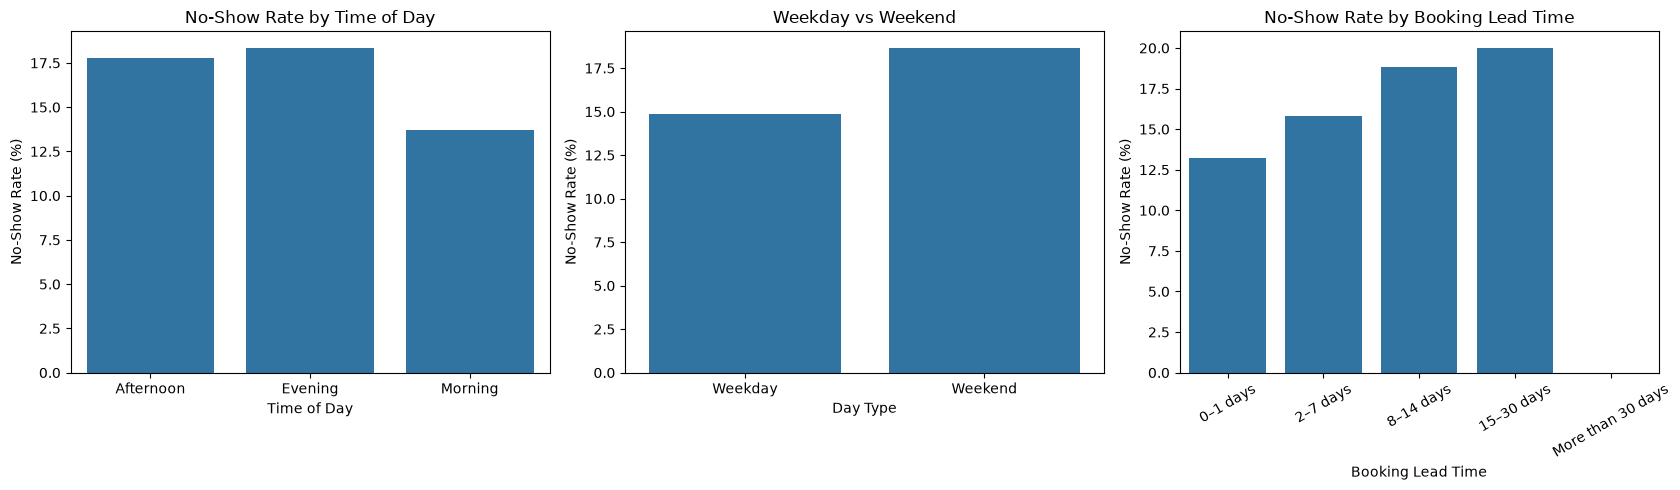

In [15]:

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

sns.barplot(
    data=time_summary.reset_index(),
    x="time_of_day",
    y="No_Show_Rate",
    ax=axes[0]
)
axes[0].set_title("No-Show Rate by Time of Day")
axes[0].set_xlabel("Time of Day")
axes[0].set_ylabel("No-Show Rate (%)")

sns.barplot(
    data=day_summary.reset_index(),
    x="Day_Type",
    y="No_Show_Rate",
    ax=axes[1]
)
axes[1].set_title("Weekday vs Weekend")
axes[1].set_xlabel("Day Type")
axes[1].set_ylabel("No-Show Rate (%)")

sns.barplot(
    data=lead_summary.reset_index(),
    x="Lead_Time_Group",
    y="No_Show_Rate",
    ax=axes[2]
)
axes[2].set_title("No-Show Rate by Booking Lead Time")
axes[2].set_xlabel("Booking Lead Time")
axes[2].set_ylabel("No-Show Rate (%)")
axes[2].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()


## 4. Which appointment types and booking channels carry the most no-show risk? 

In [16]:
# Appointment type data summary 

AppointmentType_Summary=eligible_appointments.pivot_table(
    index=["appointment_type"],
    values=["no_show_flag"],
    aggfunc=["count","sum"]
)
AppointmentType_Summary.columns=["Total_type","Total_noshows"]
AppointmentType_Summary["no_showRate"]=(AppointmentType_Summary["Total_noshows"]/AppointmentType_Summary["Total_type"])*100
AppointmentType_Summary=AppointmentType_Summary.sort_values("no_showRate",ascending = False )

AppointmentType_Summary

# booking chanel summary 
Booking_Chanel_Summary=eligible_appointments.pivot_table(
    index=["booking_channel"],
    values=["no_show_flag"],
    aggfunc=["count","sum"]
)

Booking_Chanel_Summary.columns=["Total_channel","Total_noshows"]
Booking_Chanel_Summary["no_showRate"]=(Booking_Chanel_Summary["Total_noshows"]/Booking_Chanel_Summary["Total_channel"])*100
Booking_Chanel_Summary=Booking_Chanel_Summary.sort_values("no_showRate",ascending = False)

Booking_Chanel_Summary

,Total_channel,Total_noshows,no_showRate
booking_channel,,,
Walk-In,7281,1520,20.876253
Partner App,3594,651,18.113523
Website,17964,3090,17.201069
Call Centre,10855,1650,15.200368
Apollo App,32958,4673,14.178652


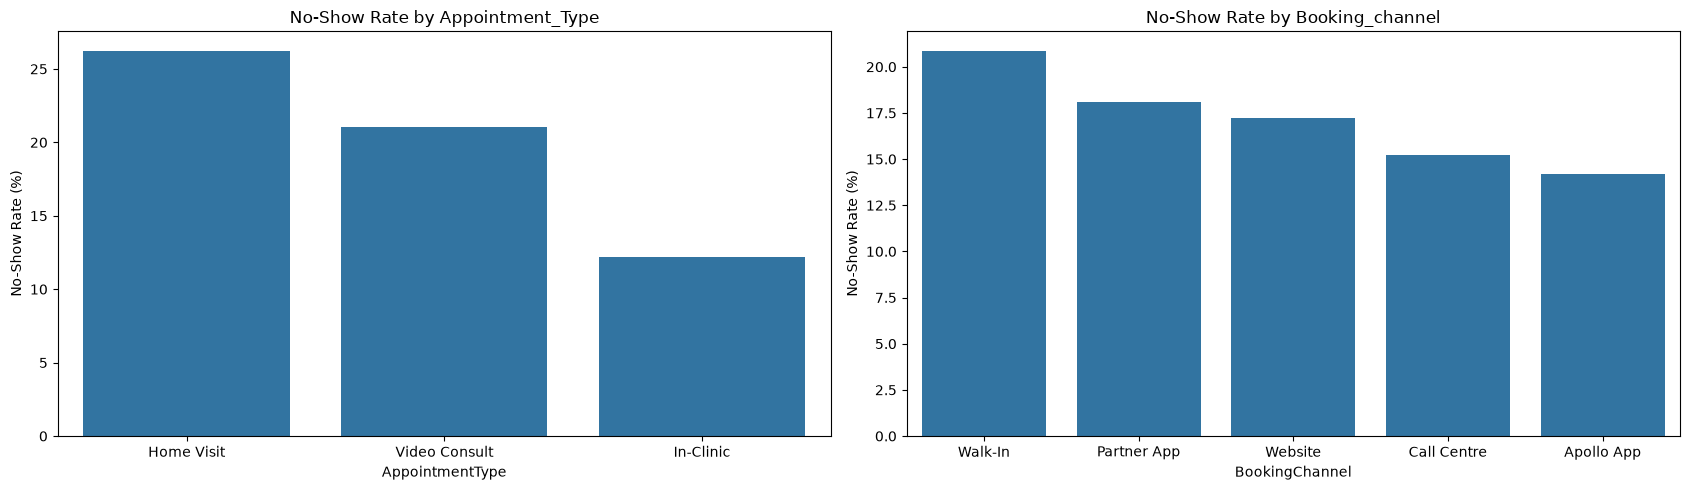

In [17]:
# Visulations 
fig, axes = plt.subplots(1, 2, figsize=(17, 5))
sns.barplot(
    data=AppointmentType_Summary,
    x="appointment_type",
    y="no_showRate",
    ax=axes[0]
)
axes[0].set_title("No-Show Rate by Appointment_Type")
axes[0].set_xlabel("AppointmentType")
axes[0].set_ylabel("No-Show Rate (%)")

sns.barplot(
    data=Booking_Chanel_Summary,
    x="booking_channel",
    y="no_showRate",
    ax=axes[1]
)
axes[1].set_title("No-Show Rate by Booking_channel")
axes[1].set_xlabel("BookingChannel")
axes[1].set_ylabel("No-Show Rate (%)")

plt.tight_layout()
plt.show()



## Reminder and Engagement Effectiveness 

## 1.How much does reminder type reduce no-show rates compared to no-reminder patients? 

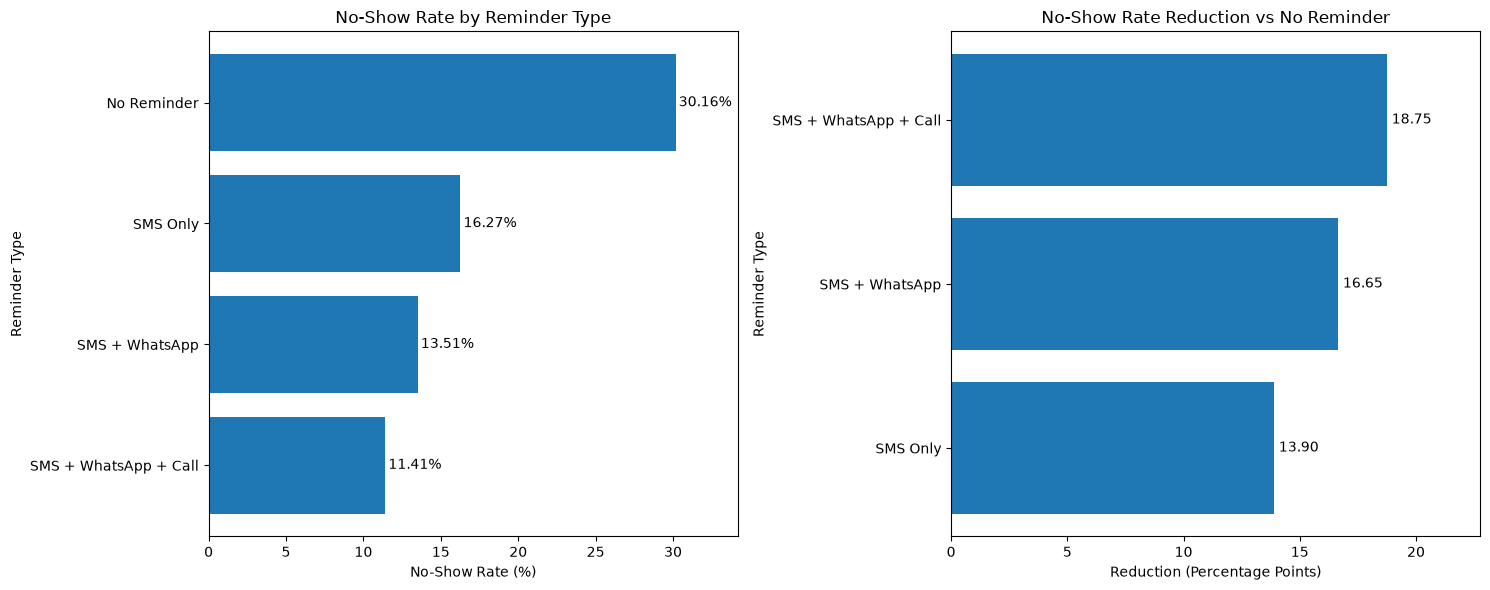

In [18]:

reminder_summary = eligible_appointments.pivot_table(
    index="reminder_type",
    values="no_show_flag",
    aggfunc=["count","sum"]
)
reminder_summary.columns = ["Total_eligible", "Total_no_shows"]

reminder_summary["No_show_rate"] = (
    reminder_summary["Total_no_shows"]
    / reminder_summary["Total_eligible"]
) * 100

reminder_summary = reminder_summary.sort_values(
    by="No_show_rate",
    ascending=False
)

no_reminder_rate = reminder_summary.loc[
    "No Reminder", "No_show_rate"
]

reminder_rates = reminder_summary.drop(index="No Reminder")

reminder_rates["Reduction_percentage_points"] = (
    no_reminder_rate - reminder_rates["No_show_rate"]
)

reminder_rates["Relative_reduction_percent"] = (
    reminder_rates["Reduction_percentage_points"]
    / no_reminder_rate
) * 100

reminder_rates
# Create two side-by-side charts
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Chart 1: No-show rate by reminder type
plot_data = reminder_summary.sort_values(
    by="No_show_rate",
    ascending=True
)

bars1 = axes[0].barh(
    plot_data.index,
    plot_data["No_show_rate"]
)

axes[0].set_title("No-Show Rate by Reminder Type")
axes[0].set_xlabel("No-Show Rate (%)")
axes[0].set_ylabel("Reminder Type")

for bar in bars1:
    width = bar.get_width()
    axes[0].text(
        width + 0.2,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.2f}%",
        va="center"
    )

axes[0].set_xlim(0, plot_data["No_show_rate"].max() + 4)

# Chart 2: Reduction compared with no-reminder patients
reduction_data = reminder_rates.sort_values(
    by="Reduction_percentage_points",
    ascending=True
)

bars2 = axes[1].barh(
    reduction_data.index,
    reduction_data["Reduction_percentage_points"]
)

axes[1].set_title("No-Show Rate Reduction vs No Reminder")
axes[1].set_xlabel("Reduction (Percentage Points)")
axes[1].set_ylabel("Reminder Type")

for bar in bars2:
    width = bar.get_width()
    axes[1].text(
        width + 0.2,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.2f}",
        va="center"
    )

axes[1].set_xlim(
    0,
    reduction_data["Reduction_percentage_points"].max() + 4
)

plt.tight_layout()
plt.show()



## 2. Does prior no-show history predict future no-show behaviour? 

                     Total_Eligible  Total_No_Shows  No_Show_Rate
Previous_No_Show                                                 
No Previous No-Show           35961            5646     15.700342
Previous No-Show               4343             888     20.446696


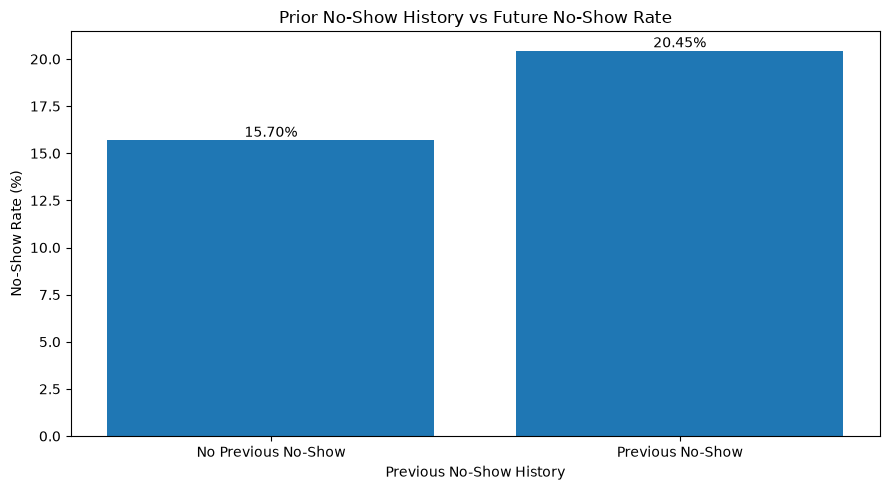

In [19]:
Appointment_data.columns.tolist()

# 1. Set the actual column names from your dataset
patient_col = "patient_id"       # Change if needed
date_col = "appointment_date"    # Change if needed

# 2. Copy data and convert appointment date to datetime
history_data = Appointment_data.copy()

history_data[date_col] = pd.to_datetime(
    history_data[date_col],
    errors="coerce"
)

# 3. Keep eligible appointments only
history_data = history_data[
    history_data["appointment_status"].isin(
        ["Completed", "No-Show", "Cancelled"]
    )
].copy()

# Remove rows missing patient ID or appointment date
history_data = history_data.dropna(
    subset=[patient_col, date_col]
)

# 4. Sort appointments by patient and date
history_data = history_data.sort_values(
    by=[patient_col, date_col]
).copy()

# 5. Identify previous no-show history
history_data["Previous_No_Show"] = (
    history_data.groupby(patient_col)["no_show_flag"]
    .transform(lambda s: s.shift(1).eq(1).cummax().shift(fill_value=False))
)

# 6. Exclude first appointments because prior history is unknown
# Keep appointments only when an earlier eligible appointment exists
history_data["Previous_Appointment_Count"] = (
    history_data.groupby(patient_col).cumcount()
)

analysis_data = history_data[
    history_data["Previous_Appointment_Count"] > 0
].copy()

# 7. Summarize no-show rates by previous history
history_summary = analysis_data.groupby(
    "Previous_No_Show"
).agg(
    Total_Eligible=("no_show_flag", "count"),
    Total_No_Shows=("no_show_flag", "sum")
)

history_summary["No_Show_Rate"] = (
    history_summary["Total_No_Shows"]
    / history_summary["Total_Eligible"]
) * 100

history_summary.index = history_summary.index.map({
    False: "No Previous No-Show",
    True: "Previous No-Show"
})

print(history_summary)

# 8. Visualize the comparison
plt.figure(figsize=(9, 5))

bars = plt.bar(
    history_summary.index,
    history_summary["No_Show_Rate"]
)

plt.title("Prior No-Show History vs Future No-Show Rate")
plt.xlabel("Previous No-Show History")
plt.ylabel("No-Show Rate (%)")

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:.2f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()



## 3. Do Apollo members and repeat patients show better attendance than non-members and first-time patients? 

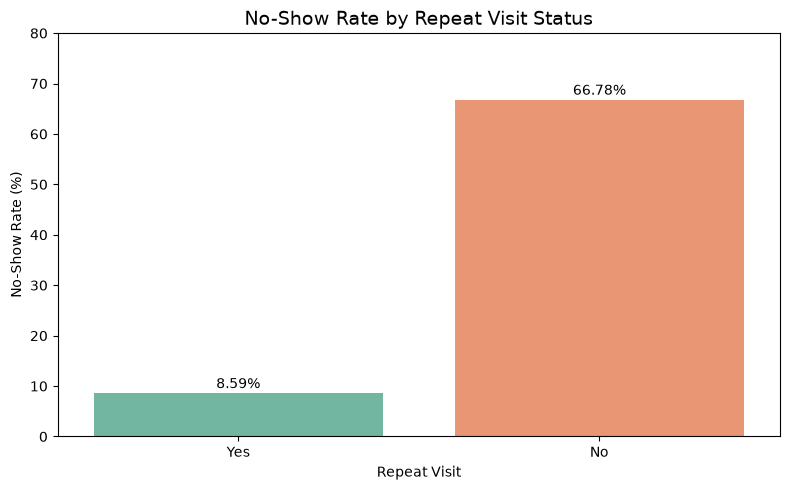

In [20]:

membership_pivot = eligible_appointments.pivot_table(
    index="membership_type",
    values="no_show_flag",
    aggfunc=["count", "sum"],
    dropna=False
)

membership_pivot.columns = ["Total_Eligible", "Total_No_Shows"]

membership_pivot["No_Show_Rate (%)"] = (
    membership_pivot["Total_No_Shows"]
    / membership_pivot["Total_Eligible"] * 100
).round(2)

membership_pivot = membership_pivot.sort_values(
    by="No_Show_Rate (%)",
    ascending=True
)

membership_pivot
repeat_pivot = eligible_appointments.pivot_table(
    index="repeat_visit",
    values="no_show_flag",
    aggfunc=["count", "sum"],
    dropna=False
)

repeat_pivot.columns = ["Total_Eligible", "Total_No_Shows"]

repeat_pivot["No_Show_Rate (%)"] = (
    repeat_pivot["Total_No_Shows"]
    / repeat_pivot["Total_Eligible"] * 100
).round(2)

repeat_pivot = repeat_pivot.sort_values(
    by="No_Show_Rate (%)",
    ascending=True
)

repeat_pivot
# Create the bar chart
plt.figure(figsize=(8, 5))

sns.barplot(
    x=repeat_pivot.index,
    y=repeat_pivot["No_Show_Rate (%)"],
    hue=repeat_pivot.index,
    palette="Set2",
    legend=False
)

# Add labels and title
plt.title("No-Show Rate by Repeat Visit Status", fontsize=14)
plt.xlabel("Repeat Visit")
plt.ylabel("No-Show Rate (%)")

# Display percentage values on top of bars
for i, value in enumerate(repeat_pivot["No_Show_Rate (%)"]):
    plt.text(i, value + 1, f"{value:.2f}%", ha="center")

plt.ylim(0, 80)
plt.tight_layout()
plt.show()

## Patient and Demographic Segmentation

## 1. How do age group, gender, and chronic condition status influence no-show likelihood? 

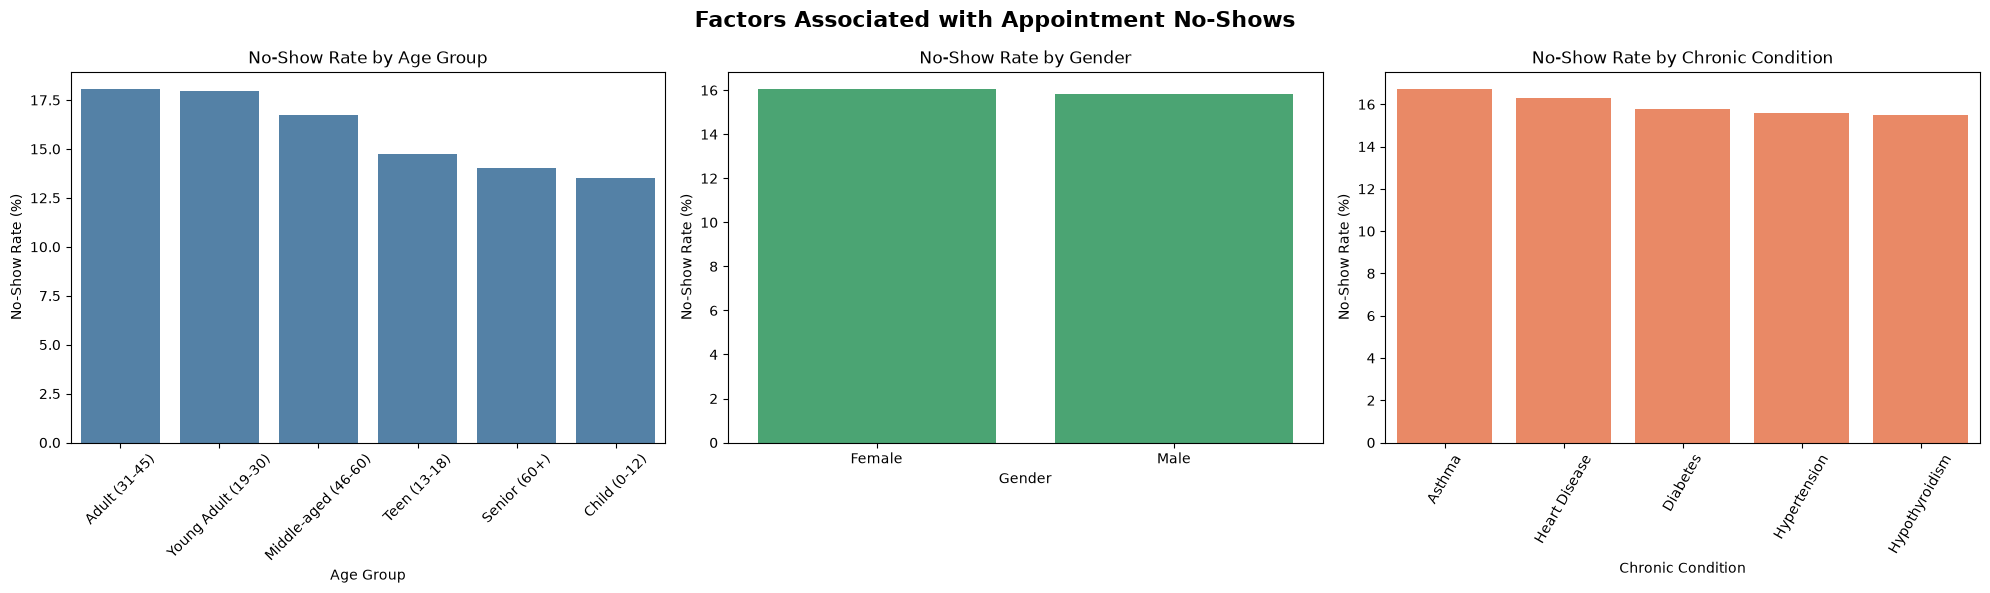

In [21]:

Appointment_data["chronic_condition_status"] = (
    Appointment_data["patient_chronic_condition"]
    .notna()
    .map({
        True: "Condition Recorded",
        False: "Condition Not Recorded"
    })
)
Appointment_data["chronic_condition_status"]

# age summary 
Age_summary=eligible_appointments.pivot_table(
    index="age_group",
    values="no_show_flag",
    aggfunc=["count","sum"]
)
Age_summary.columns=["Total_type","Total_noshows"]
Age_summary["No_Show_Rate"]=(Age_summary["Total_noshows"]/Age_summary["Total_type"])*100
Age_summary=Age_summary.sort_values("No_Show_Rate",ascending = False )
Age_summary

# gender Summary 
Gender_summary = eligible_appointments.pivot_table(
    index="patient_gender",
    values="no_show_flag",
    aggfunc=["count", "sum"]
)

Gender_summary.columns = ["Total_Eligible", "Total_No_Shows"]

Gender_summary["No_Show_Rate (%)"] = (
    Gender_summary["Total_No_Shows"]
    / Gender_summary["Total_Eligible"]
) * 100

Gender_summary = Gender_summary.sort_values(
    "No_Show_Rate (%)",
    ascending=False
)

Gender_summary

# chronic condition status Summary 
 
Chronic_summary = eligible_appointments.pivot_table(
    index="patient_chronic_condition",
    values="no_show_flag",
    aggfunc=["count", "sum"],
    dropna=False
)

Chronic_summary.columns = ["Total_Eligible", "Total_No_Shows"]

Chronic_summary["No_Show_Rate (%)"] = (
    Chronic_summary["Total_No_Shows"]
    / Chronic_summary["Total_Eligible"]
) * 100

Chronic_summary = Chronic_summary.sort_values(
    "No_Show_Rate (%)",
    ascending=False
)

Chronic_summary

# Visulizations 

# Create three subplots
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# 1. Age Group vs No-Show Rate
age_plot = Age_summary.sort_values(
    "No_Show_Rate", ascending=False
)

sns.barplot(
    x=age_plot.index.astype(str),
    y=age_plot["No_Show_Rate"],
    ax=axes[0],
    color="steelblue"
)

axes[0].set_title("No-Show Rate by Age Group")
axes[0].set_xlabel("Age Group")
axes[0].set_ylabel("No-Show Rate (%)")
axes[0].tick_params(axis="x", rotation=45)



# 2. Gender vs No-Show Rate
gender_plot = Gender_summary.sort_values(
    "No_Show_Rate (%)", ascending=False
)

sns.barplot(
    x=gender_plot.index.astype(str),
    y=gender_plot["No_Show_Rate (%)"],
    ax=axes[1],
    color="mediumseagreen"
)

axes[1].set_title("No-Show Rate by Gender")
axes[1].set_xlabel("Gender")
axes[1].set_ylabel("No-Show Rate (%)")

# 3. Chronic Condition vs No-Show Rate
chronic_plot = Chronic_summary.sort_values(
    "No_Show_Rate (%)", ascending=False
)

sns.barplot(
    x=chronic_plot.index.astype(str),
    y=chronic_plot["No_Show_Rate (%)"],
    ax=axes[2],
    color="coral"
)

axes[2].set_title("No-Show Rate by Chronic Condition")
axes[2].set_xlabel("Chronic Condition")
axes[2].set_ylabel("No-Show Rate (%)")
axes[2].tick_params(axis="x", rotation=60)

# Main title and layout
fig.suptitle(
    "Factors Associated with Appointment No-Shows",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()




## 2. Which visit reasons are most common and are some associated with higher dropout? 

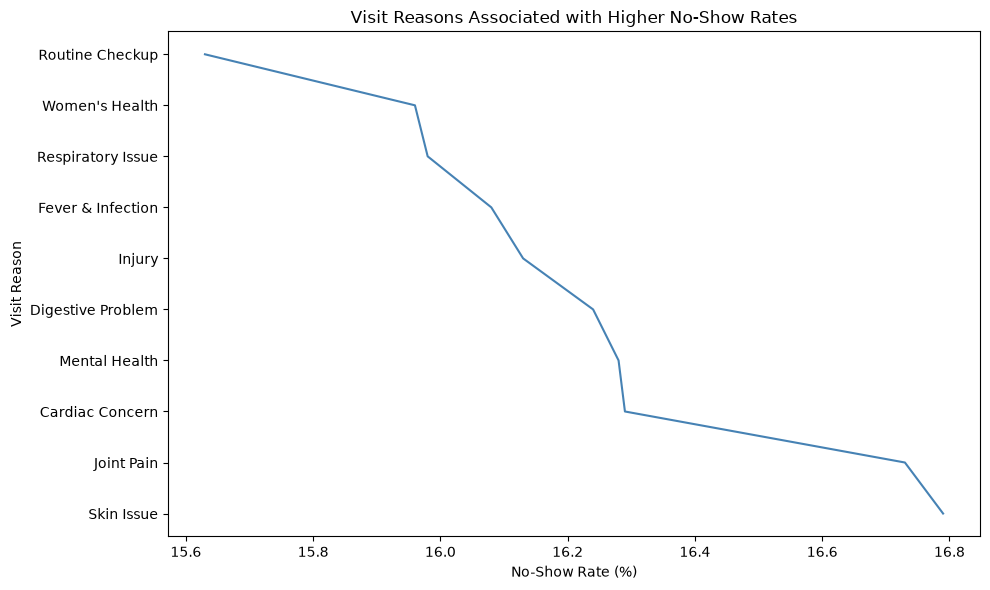

In [22]:

visit_reason_summary = eligible_appointments.pivot_table(
    index="visit_reason",
    values="no_show_flag",
    aggfunc=["count", "sum"]
)

visit_reason_summary.columns = [
    "Total_Eligible",
    "Total_No_Shows"
]

visit_reason_summary["No_Show_Rate (%)"] = (
    visit_reason_summary["Total_No_Shows"]
    / visit_reason_summary["Total_Eligible"] * 100
).round(2)

visit_reason_summary = visit_reason_summary.sort_values(
    by="No_Show_Rate (%)",
    ascending=False
)

visit_reason_summary

reliable_reasons = visit_reason_summary[
    visit_reason_summary["Total_Eligible"] >= 100
].sort_values(
    by="No_Show_Rate (%)",
    ascending=False
)

reliable_reasons.head(5)

# Visulizations 

plot_data = reliable_reasons.head(10).sort_values(
    "No_Show_Rate (%)",
    ascending=True
)

plt.figure(figsize=(10, 6))

sns.lineplot(
    data=plot_data,
    x="No_Show_Rate (%)",
    y=plot_data.index.astype(str),
    color="steelblue"
)

plt.title("Visit Reasons Associated with Higher No-Show Rates")
plt.xlabel("No-Show Rate (%)")
plt.ylabel("Visit Reason")
plt.tight_layout()
plt.show()


## 3. What does the patient age distribution look like within specialties like Paediatrics, Gynaecology, and Psychiatry? 

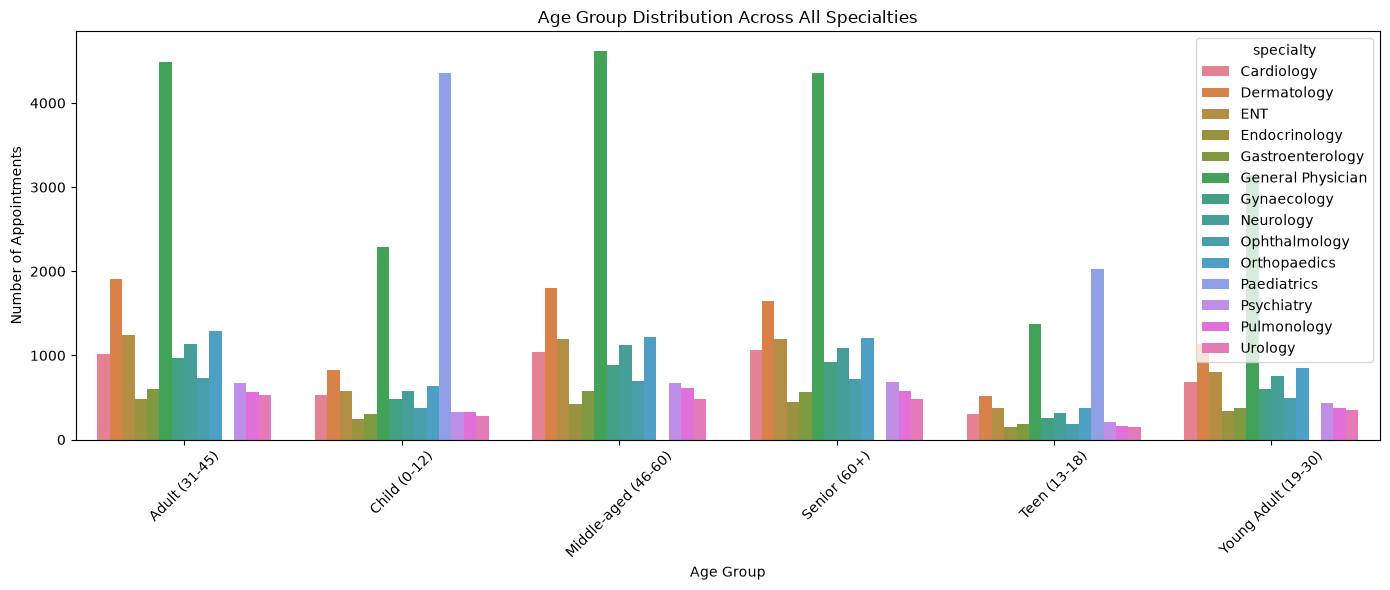

In [23]:

age_specialty_summary = Appointment_data.pivot_table(
    index="age_group",
    columns="specialty",
    aggfunc="size",
    fill_value=0
)

age_specialty_summary 

# ViSulizations 
plot_data = age_specialty_summary.reset_index().melt(
    id_vars="age_group",
    var_name="specialty",
    value_name="appointments"
)

plt.figure(figsize=(14, 6))
sns.barplot(data=plot_data, x="age_group", y="appointments", hue="specialty")

plt.title("Age Group Distribution Across All Specialties")
plt.xlabel("Age Group")
plt.ylabel("Number of Appointments")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Financial Performance

## 1. How much revenue is being lost to no-shows? 

Total No-Shows: 11584
Estimated Potential Revenue Loss: 15485947.64


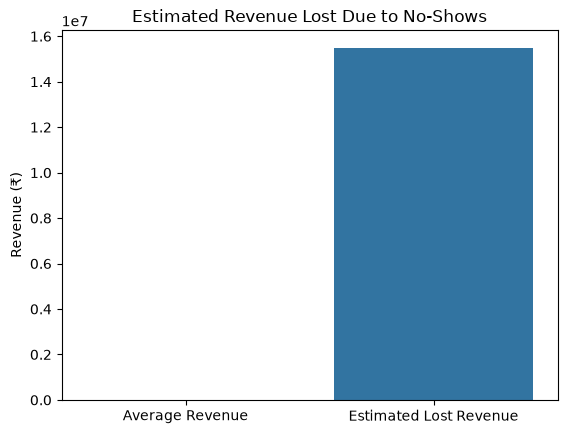

In [49]:
# Average revenue per completed appointment
avg_revenue = Appointment_data.loc[
    Appointment_data["appointment_status"] == "Completed",
    "revenue_realized"
].mean()

# Total no-show appointments
total_no_shows = (Appointment_data["no_show"] == "Yes").sum()

# Estimated potential revenue loss
lost_revenue = avg_revenue * total_no_shows

print("Total No-Shows:", total_no_shows)
print("Estimated Potential Revenue Loss:", round(lost_revenue, 2))
 # visulizations 
sns.barplot(
    x=["Average Revenue", "Estimated Lost Revenue"],
    y=[avg_revenue, lost_revenue]
)

plt.title("Estimated Revenue Lost Due to No-Shows")
plt.ylabel("Revenue (₹)")
plt.xlabel("")

plt.show()

## 2. How does average revenue vary across specialties and appointment types? 

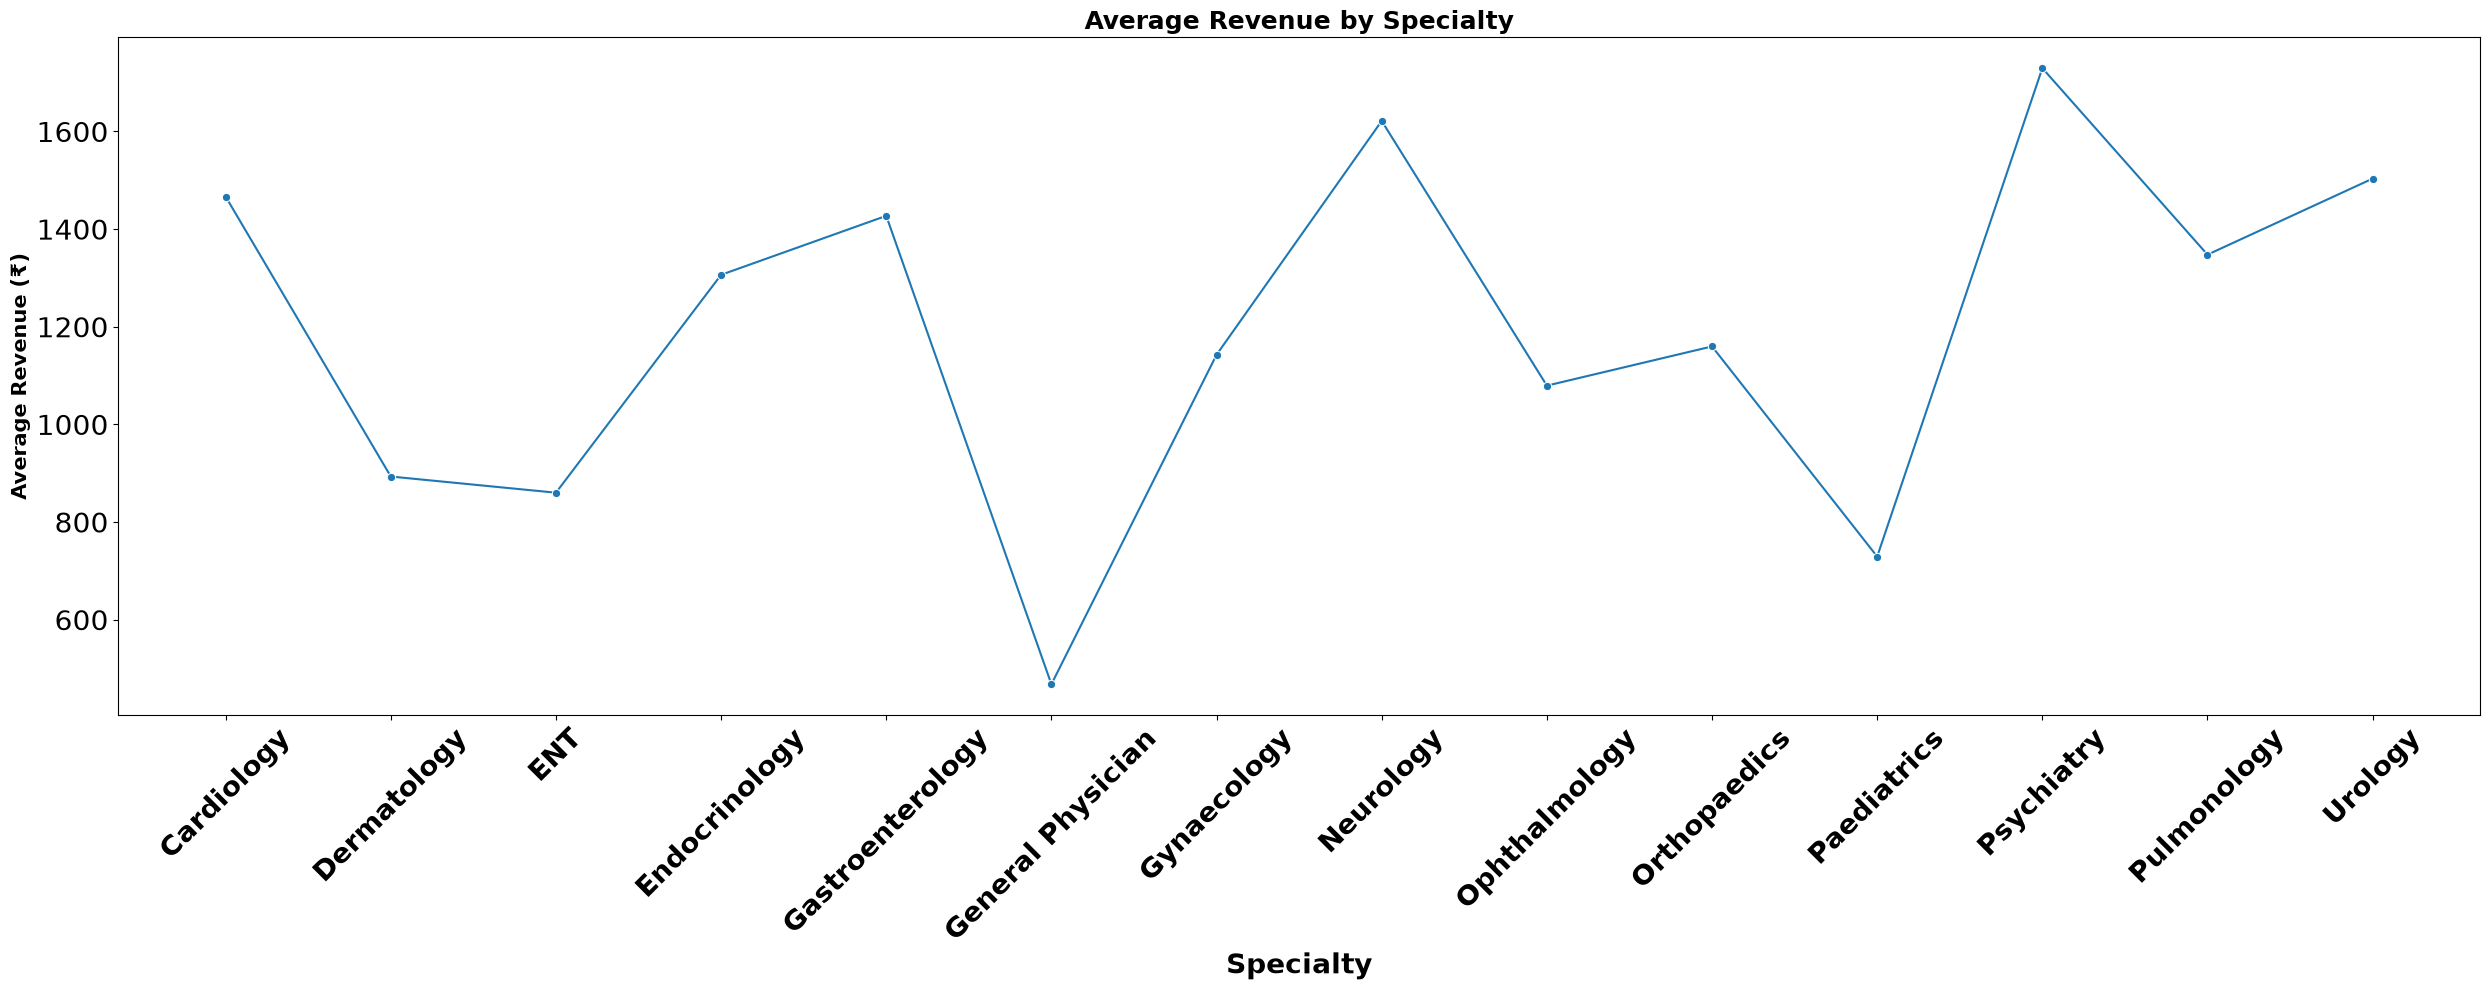

In [58]:
# Specialties_revenue
Specialties_revenue=Appointment_data.pivot_table(
    index="specialty",
    values="revenue_realized",
    aggfunc="mean"
)
Specialties_revenue.columns=["avg_revenue"]
Specialties_revenue


# Appointment_type _revenue 
Appointment_type_revenue=Appointment_data.pivot_table(
    index="appointment_type",
    values="revenue_realized",
    aggfunc="mean"
)
Appointment_type_revenue.columns=["avg_revenue"]

# Visulizations  for Speciality 
plt.figure(figsize=(25, 10))

sns.lineplot(
    data=Specialties_revenue,
    x="specialty",
    y="avg_revenue",
    marker="o"
)

plt.title("Average Revenue by Specialty", fontsize=18, fontweight="bold")
plt.xlabel("Specialty", fontsize=20, fontweight="bold")
plt.ylabel("Average Revenue (₹)", fontsize=15, fontweight="bold")

# X-axis labels bold and larger
plt.xticks(rotation=45, fontsize=20, fontweight="bold")
plt.yticks(fontsize=20)

plt.tight_layout()
plt.show()


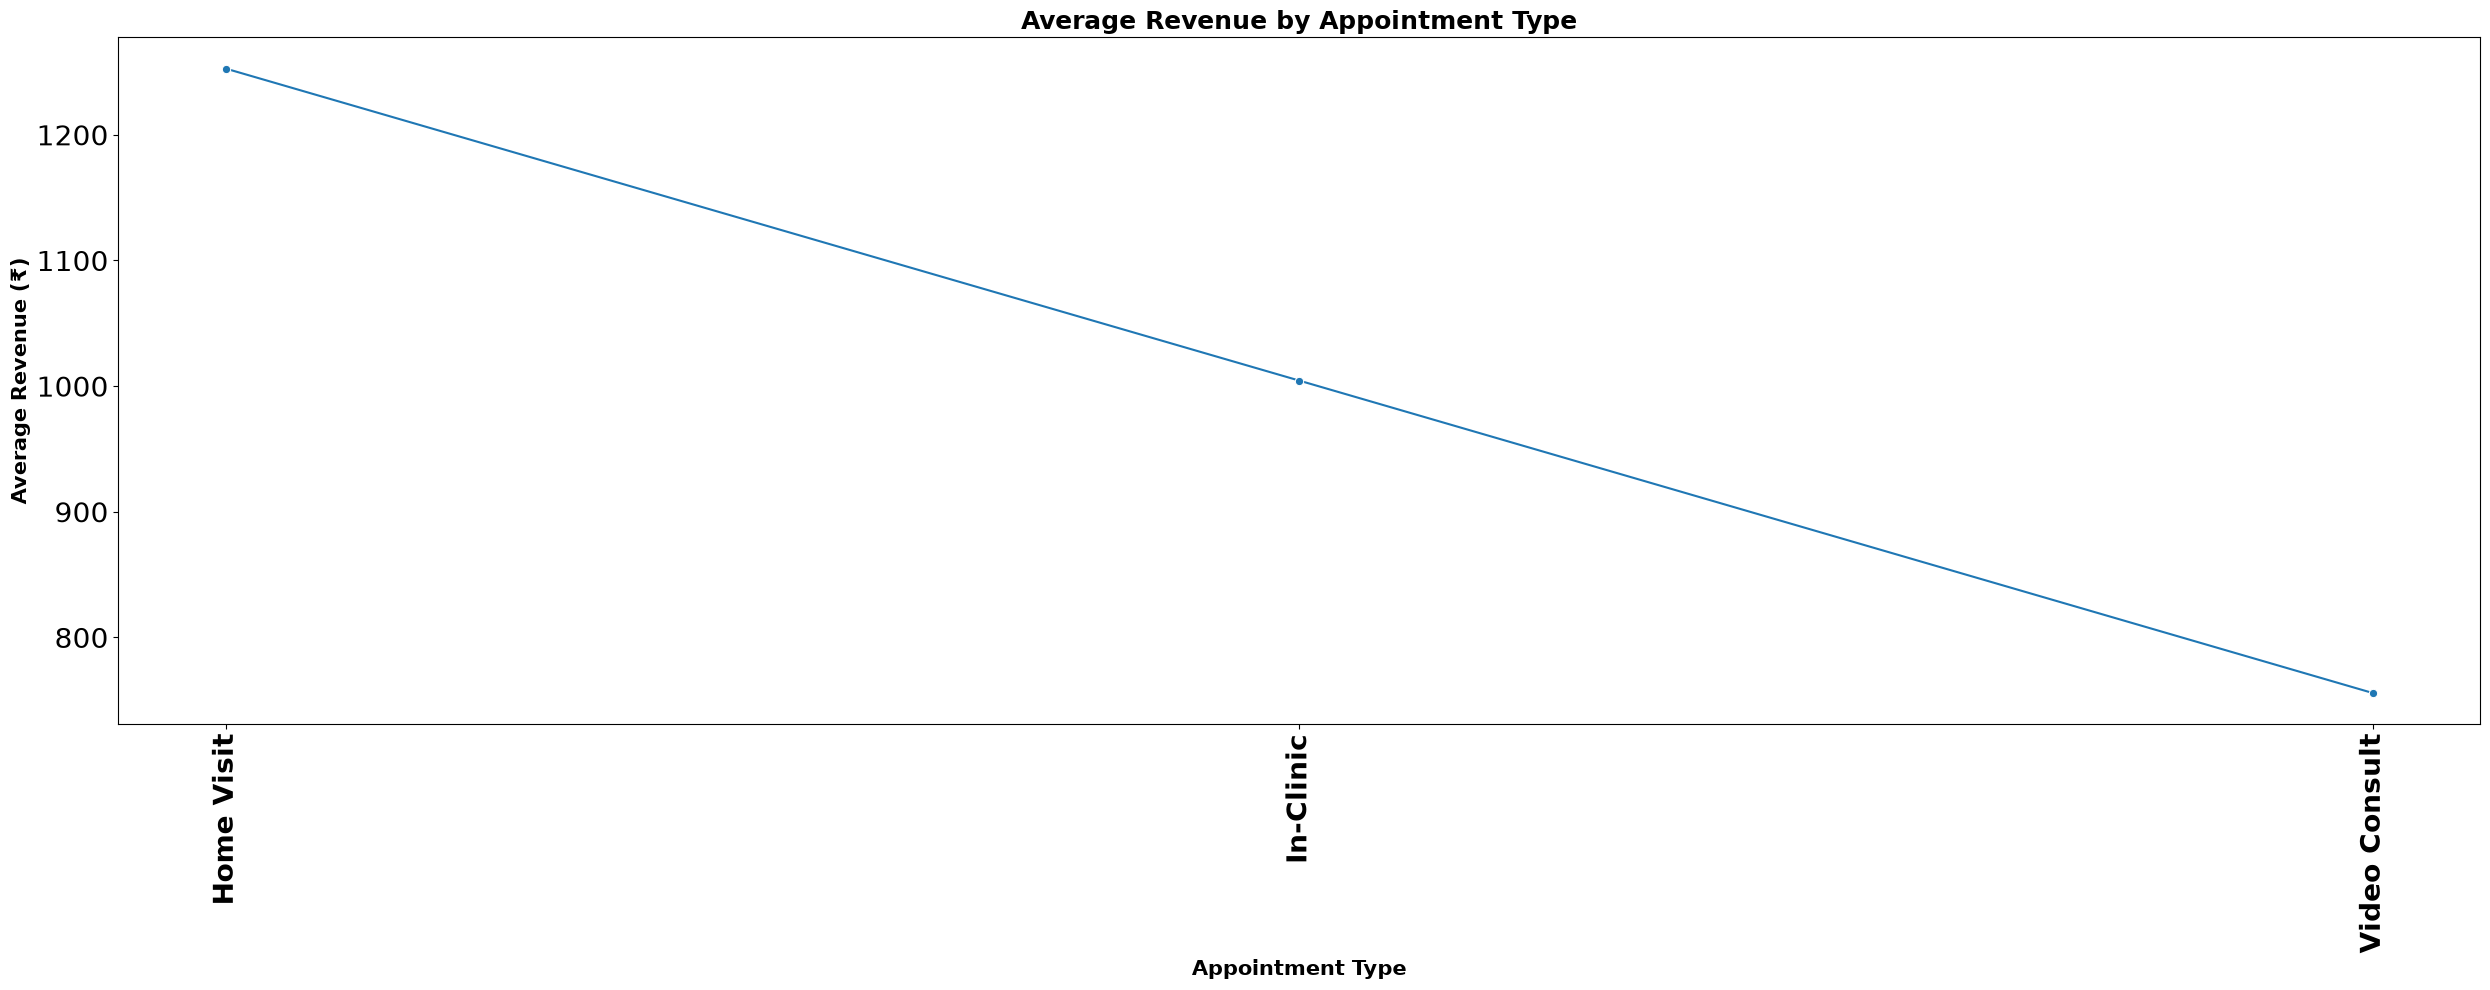

In [59]:
# visulization for Appointment Type 

plt.figure(figsize=(25, 10))

sns.lineplot(
    data=Appointment_type_revenue,
    x="appointment_type",
    y="avg_revenue",
    marker="o"
)

plt.title("Average Revenue by Appointment Type", fontsize=18, fontweight="bold")
plt.xlabel("Appointment Type", fontsize=15, fontweight="bold")
plt.ylabel("Average Revenue (₹)", fontsize=15, fontweight="bold")

plt.xticks(rotation=90, fontsize=20, fontweight="bold")
plt.yticks(fontsize=20)

plt.tight_layout()
plt.show()

## 3. Which cities generate the most revenue and what is the payment mode mix? 

In [29]:
# City-wise revenue
City_revenue = Appointment_data.groupby("city", as_index=False).agg(
    total_revenue=("revenue_realized", "sum")
)

City_revenue = City_revenue.sort_values(
    "total_revenue", ascending=False
)

City_revenue


,city,total_revenue
1,Bengaluru,9990616
6,Delhi,9958247
13,Mumbai,8989613
7,Hyderabad,7503245
4,Chennai,7188473
11,Kolkata,6543084
14,Pune,4734139
0,Ahmedabad,3956890
12,Lucknow,3177444
8,Indore,2223207


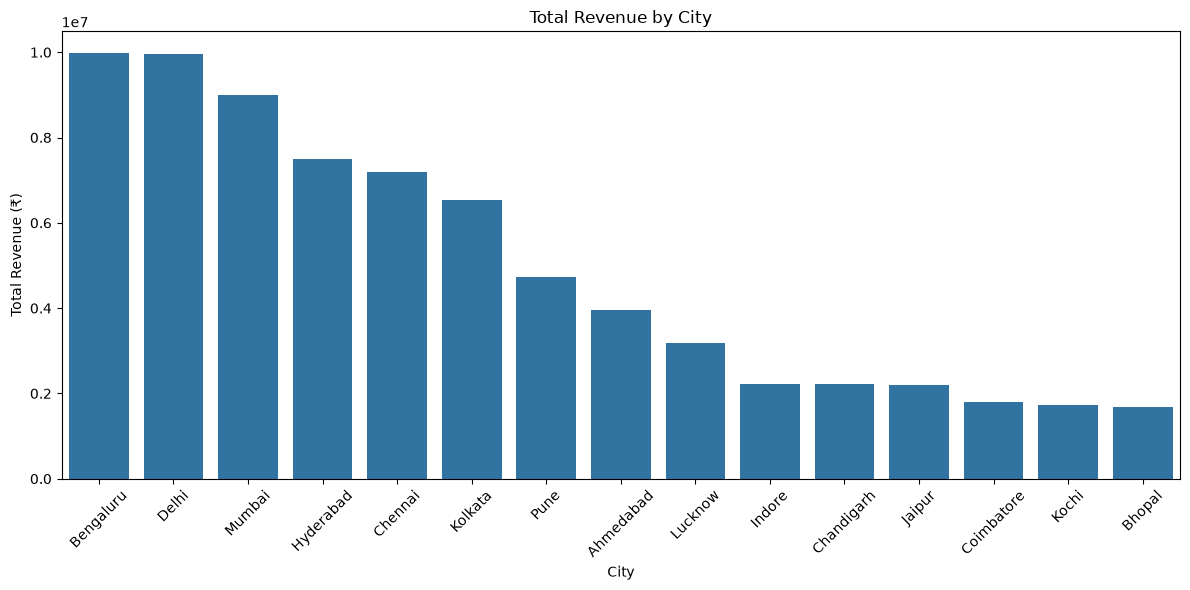

In [30]:
# visulizations 
plt.figure(figsize=(12, 6))

sns.barplot(data=City_revenue, x="city", y="total_revenue")

plt.title("Total Revenue by City")
plt.xlabel("City")
plt.ylabel("Total Revenue (₹)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

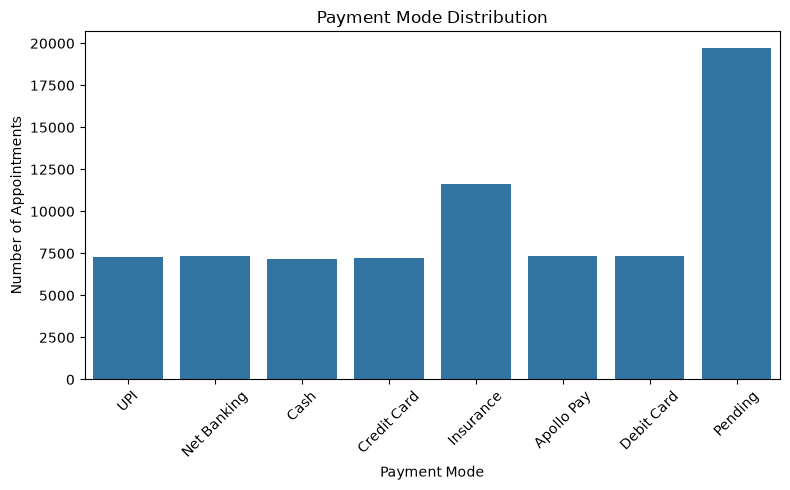

In [31]:
#Payment mode mix
Appointment_data["payment_mode"].value_counts()
plt.figure(figsize=(8, 5))

sns.countplot(data=Appointment_data, x="payment_mode")

plt.title("Payment Mode Distribution")
plt.xlabel("Payment Mode")
plt.ylabel("Number of Appointments")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 4. How does insurance coverage affect what patients pay out of pocket? 

In [32]:
Insurance_summary = Appointment_data.groupby(
    "insurance_coverage", as_index=False
).agg(
    total_patients=("patient_out_of_pocket", "count"),
    avg_out_of_pocket=("patient_out_of_pocket", "mean")
)

Insurance_summary


,insurance_coverage,total_patients,avg_out_of_pocket
0,No,51512,1138.408914
1,Yes,23488,649.356182


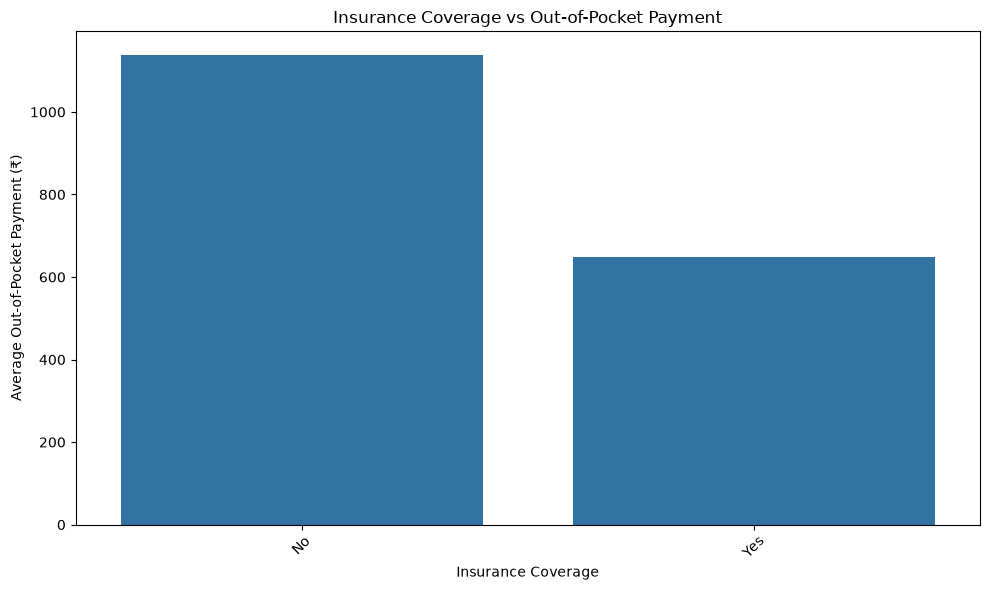

In [33]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=Insurance_summary,
    x="insurance_coverage",
    y="avg_out_of_pocket",
    errorbar=None
)

plt.title("Insurance Coverage vs Out-of-Pocket Payment")
plt.xlabel("Insurance Coverage")
plt.ylabel("Average Out-of-Pocket Payment (₹)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## Doctor Utilisation and Service Quality 

## 1. Which specialties have the highest and lowest doctor utilisation rates? 

In [62]:
doctor_usage = Appointment_data.groupby(
    "doctor_id"
).size().reset_index(name="total_appointments")

# Add doctor specialty
doctor_usage = doctor_usage.merge(
    Apollo_doctor[["doctor_id", "specialty"]],
    on="doctor_id",
    how="left"
)

# Calculate specialty-wise appointments
Specialty_usage = doctor_usage.groupby(
    "specialty", as_index=False
)["total_appointments"].sum()

Specialty_usage = Specialty_usage.sort_values(
    "total_appointments", ascending=False
)

Specialty_usage

,specialty,total_appointments
5,General Physician,20272
1,Dermatology,7824
10,Paediatrics,6382
9,Orthopaedics,5589
2,ENT,5385
7,Neurology,4993
0,Cardiology,4641
6,Gynaecology,4113
8,Ophthalmology,3193
11,Psychiatry,2989


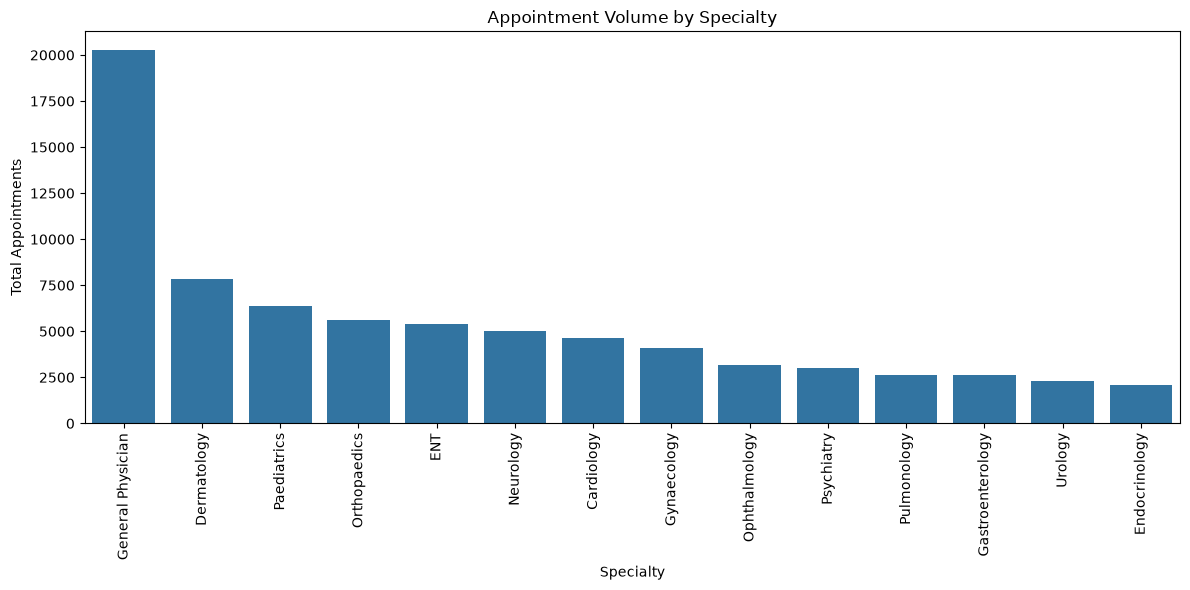

In [65]:
# Visulizations 
plt.figure(figsize=(12, 6))

sns.barplot(
    data=Specialty_usage,
    x="specialty",
    y="total_appointments"
)

plt.title("Appointment Volume by Specialty")
plt.xlabel("Specialty")
plt.ylabel("Total Appointments")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

## 2. How long are patients waiting and does it vary by specialty or time of day? 

In [36]:

Waiting_summary = Appointment_data.groupby(
    ["specialty", "time_of_day"],
    as_index=False
).agg(
    avg_wait_time=("wait_time_minutes", "mean")
)

Waiting_summary["avg_wait_time"] = (
    Waiting_summary["avg_wait_time"].round(2)
)

Waiting_summary


,specialty,time_of_day,avg_wait_time
0,Cardiology,Afternoon,11.88
1,Cardiology,Evening,11.37
2,Cardiology,Morning,11.50
3,Dermatology,Afternoon,11.68
4,Dermatology,Evening,10.77
5,Dermatology,Morning,12.23
6,ENT,Afternoon,11.56
7,ENT,Evening,11.33
8,ENT,Morning,11.11
9,Endocrinology,Afternoon,11.10


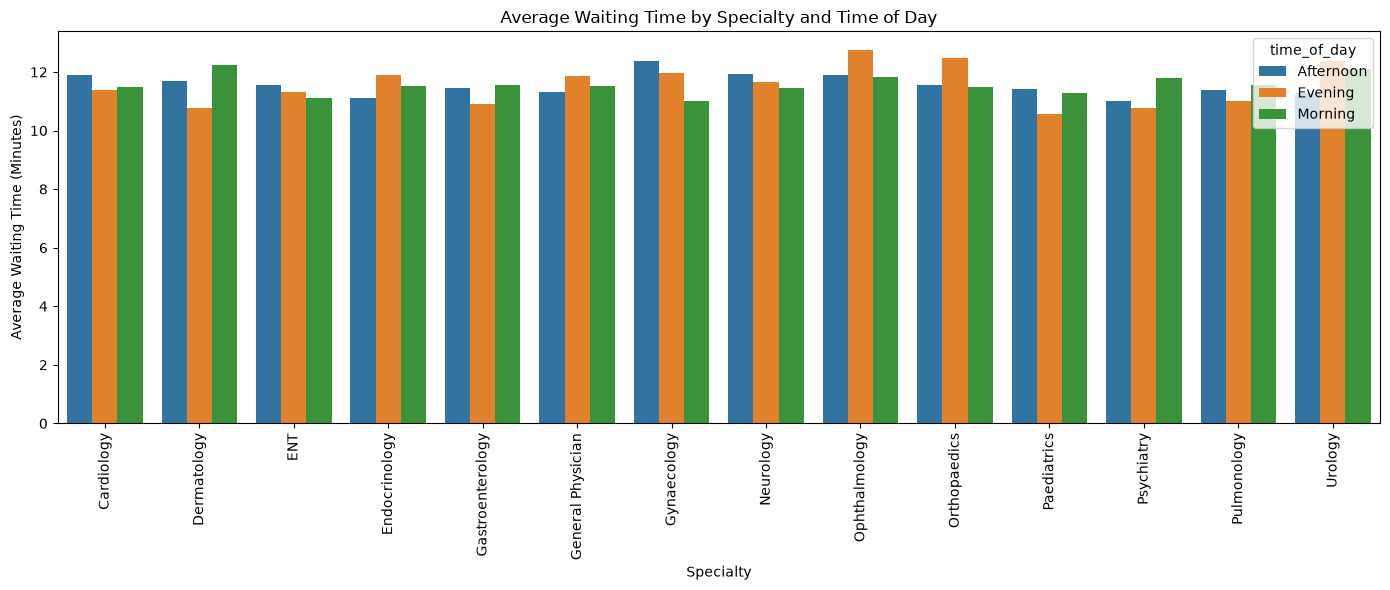

In [61]:
# visulizations 

plt.figure(figsize=(14, 6))

sns.barplot(
    data=Waiting_summary,
    x="specialty",
    y="avg_wait_time",
    hue="time_of_day",
    errorbar=None
)

plt.title("Average Waiting Time by Specialty and Time of Day")
plt.xlabel("Specialty")
plt.ylabel("Average Waiting Time (Minutes)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


## 3. Is there a relationship between consultation duration and patient satisfaction? 

In [38]:

Duration_summary = Appointment_data[
    ["consultation_duration_min", "patient_satisfaction_score"]
].dropna()

print(
    Duration_summary.corr().round(2)
)



                            consultation_duration_min  \
consultation_duration_min                         1.0   
patient_satisfaction_score                       -0.0   

                            patient_satisfaction_score  
consultation_duration_min                         -0.0  
patient_satisfaction_score                         1.0  


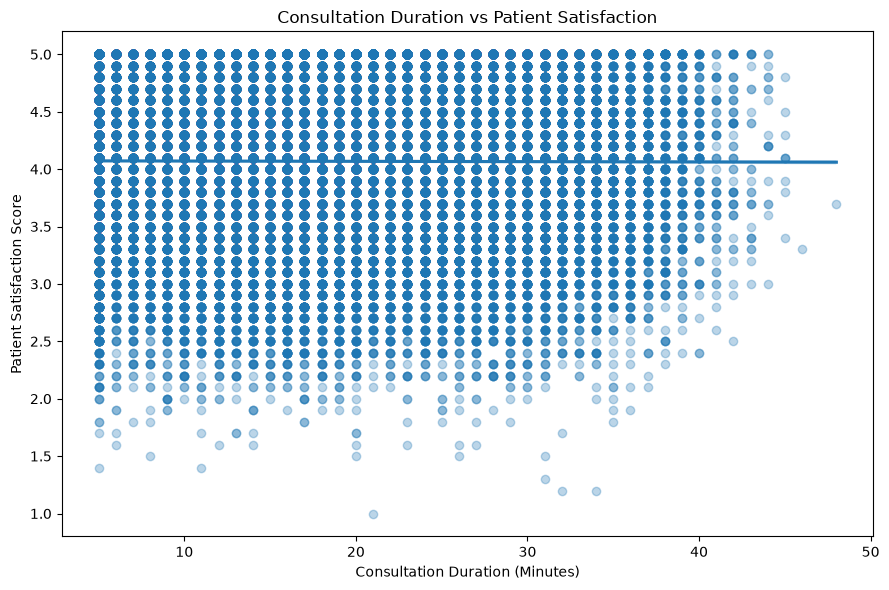

In [39]:
# Visulizations 

plt.figure(figsize=(9, 6))

sns.regplot(
    data=Duration_summary,
    x="consultation_duration_min",
    y="patient_satisfaction_score",
    scatter_kws={"alpha": 0.3}
)

plt.title("Consultation Duration vs Patient Satisfaction")
plt.xlabel("Consultation Duration (Minutes)")
plt.ylabel("Patient Satisfaction Score")
plt.tight_layout()
plt.show()



## 4. How does doctor experience relate to the fee charged (join with doctors dim)? 

In [40]:

Experience_fee = Apollo_doctor.groupby(
    "experience_years",
    as_index=False
).agg(
    avg_consultation_fee=("consultation_fee", "mean"),
    total_doctors=("doctor_id", "count")
)

Experience_fee["avg_consultation_fee"] = (
    Experience_fee["avg_consultation_fee"].round(2)
)

Experience_fee


,experience_years,avg_consultation_fee,total_doctors
0,2,1314.29,21
1,3,1140.00,5
2,4,1393.33,15
3,5,1310.00,10
4,6,1640.00,10
5,7,1361.54,13
6,8,1442.86,14
7,9,1136.36,11
8,10,1658.33,12
9,11,1377.78,9


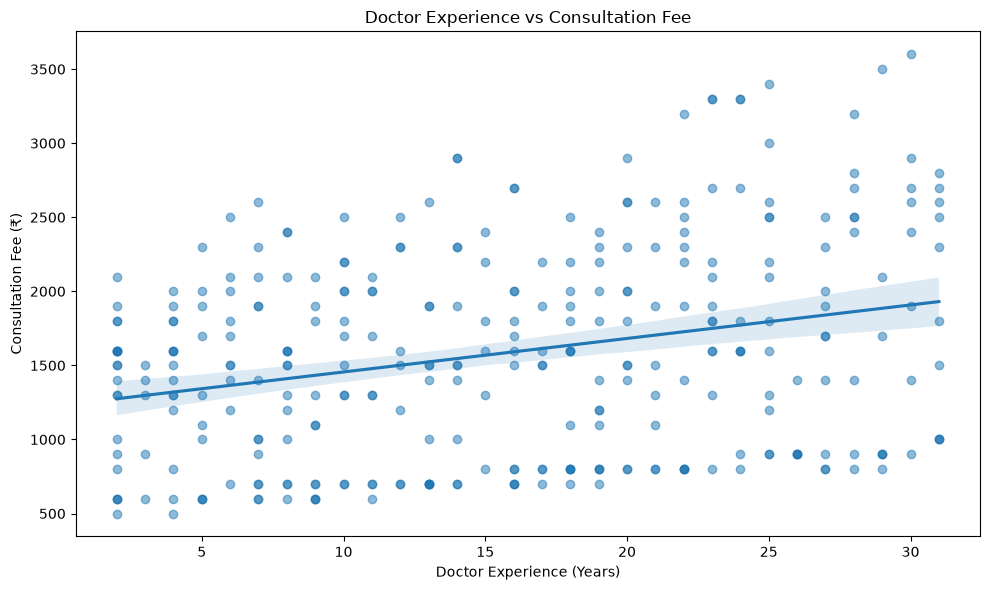

In [41]:
# Visulizations 

plt.figure(figsize=(10, 6))

sns.regplot(
    data=Apollo_doctor,
    x="experience_years",
    y="consultation_fee",
    scatter_kws={"alpha": 0.5}
)

plt.title("Doctor Experience vs Consultation Fee")
plt.xlabel("Doctor Experience (Years)")
plt.ylabel("Consultation Fee (₹)")
plt.tight_layout()
plt.show()
